In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, DBSCAN
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE

from sklearn.metrics import silhouette_score

In [33]:
from google.colab import files

uploaded = files.upload()

file_name = next(iter(uploaded))

df = pd.read_csv(
    file_name,
    encoding='latin1'
)

print(df.head())
print(df.shape)

Saving OnlineRetail.csv to OnlineRetail (2).csv
  InvoiceNo StockCode                          Description  Quantity  \
0    536365    85123A   WHITE HANGING HEART T-LIGHT HOLDER         6   
1    536365     71053                  WHITE METAL LANTERN         6   
2    536365    84406B       CREAM CUPID HEARTS COAT HANGER         8   
3    536365    84029G  KNITTED UNION FLAG HOT WATER BOTTLE         6   
4    536365    84029E       RED WOOLLY HOTTIE WHITE HEART.         6   

      InvoiceDate  UnitPrice  CustomerID         Country  
0  12/1/2010 8:26       2.55     17850.0  United Kingdom  
1  12/1/2010 8:26       3.39     17850.0  United Kingdom  
2  12/1/2010 8:26       2.75     17850.0  United Kingdom  
3  12/1/2010 8:26       3.39     17850.0  United Kingdom  
4  12/1/2010 8:26       3.39     17850.0  United Kingdom  
(541909, 8)


In [34]:
df.shape

(541909, 8)

In [35]:
df.isnull().sum()

,0
InvoiceNo,0
StockCode,0
Description,1454
Quantity,0
InvoiceDate,0
UnitPrice,0
CustomerID,135080
Country,0


In [36]:
df = df.dropna(subset=['CustomerID'])

In [37]:
df = df[~df['InvoiceNo'].astype(str).str.startswith('C')]

In [38]:
df = df[(df['Quantity'] > 0) & (df['UnitPrice'] > 0)]

In [39]:
print(df.shape)
print(df.isnull().sum())
print(df.head())

(397884, 8)
InvoiceNo      0
StockCode      0
Description    0
Quantity       0
InvoiceDate    0
UnitPrice      0
CustomerID     0
Country        0
dtype: int64
  InvoiceNo StockCode                          Description  Quantity  \
0    536365    85123A   WHITE HANGING HEART T-LIGHT HOLDER         6   
1    536365     71053                  WHITE METAL LANTERN         6   
2    536365    84406B       CREAM CUPID HEARTS COAT HANGER         8   
3    536365    84029G  KNITTED UNION FLAG HOT WATER BOTTLE         6   
4    536365    84029E       RED WOOLLY HOTTIE WHITE HEART.         6   

      InvoiceDate  UnitPrice  CustomerID         Country  
0  12/1/2010 8:26       2.55     17850.0  United Kingdom  
1  12/1/2010 8:26       3.39     17850.0  United Kingdom  
2  12/1/2010 8:26       2.75     17850.0  United Kingdom  
3  12/1/2010 8:26       3.39     17850.0  United Kingdom  
4  12/1/2010 8:26       3.39     17850.0  United Kingdom  


In [40]:
df['TotalAmount'] = df['Quantity'] * df['UnitPrice']

In [41]:
df['InvoiceDate'] = pd.to_datetime(df['InvoiceDate'])

In [42]:
reference_date = df['InvoiceDate'].max() + pd.Timedelta(days=1)

In [43]:
rfm = df.groupby('CustomerID').agg({
    'InvoiceDate': lambda x: (reference_date - x.max()).days,
    'InvoiceNo': 'nunique',
    'TotalAmount': 'sum'
})

rfm.columns = ['Recency', 'Frequency', 'Monetary']

print(rfm.head())

            Recency  Frequency  Monetary
CustomerID                              
12346.0         326          1  77183.60
12347.0           2          7   4310.00
12348.0          75          4   1797.24
12349.0          19          1   1757.55
12350.0         310          1    334.40


In [44]:
df.shape

(397884, 9)

In [45]:
rfm.head()

,Recency,Frequency,Monetary
CustomerID,,,
12346.0,326,1,77183.60
12347.0,2,7,4310.00
12348.0,75,4,1797.24
12349.0,19,1,1757.55
12350.0,310,1,334.40


In [46]:
rfm_features = rfm[
    ['Recency', 'Frequency', 'Monetary']
].copy()

rfm_log = np.log1p(rfm_features)

scaler = StandardScaler()

rfm_scaled = scaler.fit_transform(rfm_log)

print(rfm_scaled[:5])

[[ 1.46199281 -0.95521426  3.70622476]
 [-2.03873442  1.07442519  1.41184341]
 [ 0.37310424  0.38630445  0.7164889 ]
 [-0.62308592 -0.95521426  0.6987394 ]
 [ 1.42455753 -0.95521426 -0.6189622 ]]


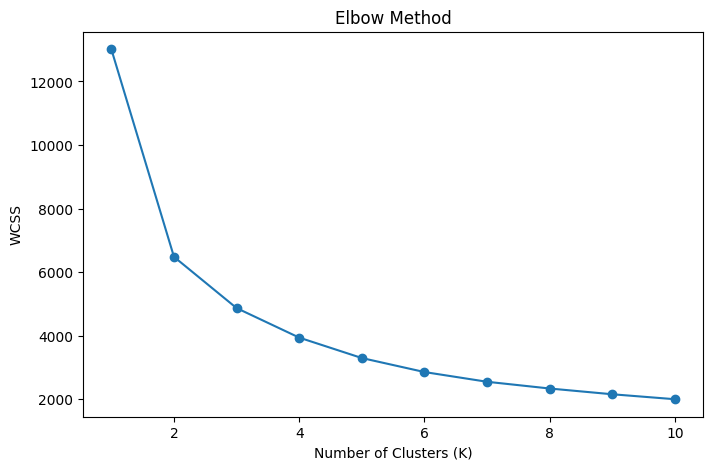

In [47]:
wcss = []

for i in range(1, 11):
    kmeans = KMeans(
        n_clusters=i,
        random_state=42,
        n_init=10
    )

    kmeans.fit(rfm_scaled)

    wcss.append(kmeans.inertia_)

plt.figure(figsize=(8, 5))
plt.plot(range(1, 11), wcss, marker='o')

plt.xlabel('Number of Clusters (K)')
plt.ylabel('WCSS')
plt.title('Elbow Method')
plt.show()

K = 2 Score = 0.43294018131896617
K = 3 Score = 0.33650963406696927
K = 4 Score = 0.3371343622222519
K = 5 Score = 0.31609724178691406
K = 6 Score = 0.31332900440932415
K = 7 Score = 0.3099750749146704
K = 8 Score = 0.3007815604390329
K = 9 Score = 0.2816531703125976
K = 10 Score = 0.2786648925494945


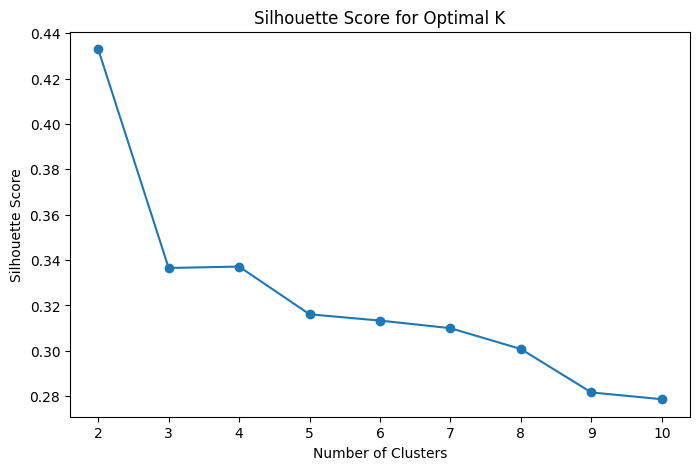

In [48]:
scores = []

for k in range(2, 11):

    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = model.fit_predict(rfm_scaled)

    score = silhouette_score(
        rfm_scaled,
        labels
    )

    scores.append(score)

    print("K =", k, "Score =", score)

plt.figure(figsize=(8, 5))

plt.plot(
    range(2, 11),
    scores,
    marker='o'
)

plt.xlabel("Number of Clusters")
plt.ylabel("Silhouette Score")
plt.title("Silhouette Score for Optimal K")
plt.show()

In [49]:
kmeans = KMeans(
    n_clusters=4,
    random_state=42,
    n_init=10
)

rfm['KMeans_Cluster'] = kmeans.fit_predict(rfm_scaled)

print(rfm.head())

            Recency  Frequency  Monetary  KMeans_Cluster
CustomerID                                              
12346.0         326          1  77183.60               2
12347.0           2          7   4310.00               1
12348.0          75          4   1797.24               2
12349.0          19          1   1757.55               0
12350.0         310          1    334.40               3


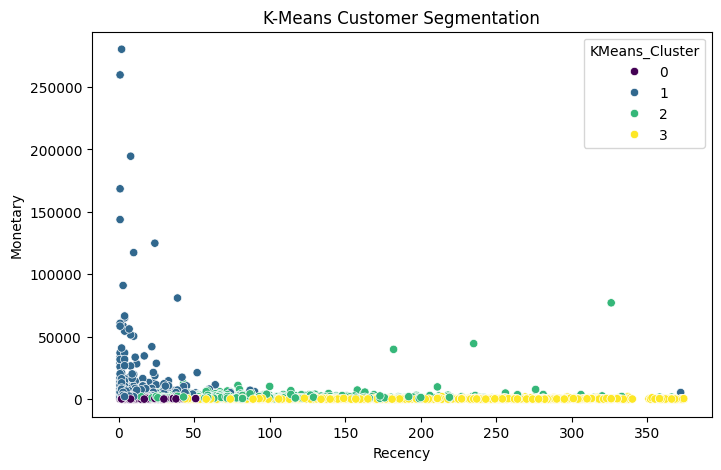

In [50]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    x=rfm['Recency'],
    y=rfm['Monetary'],
    hue=rfm['KMeans_Cluster'],
    palette='viridis'
)

plt.title('K-Means Customer Segmentation')
plt.show()

In [51]:
for eps in [0.3, 0.5, 0.7, 1.0, 1.2, 1.5]:

    model = DBSCAN(
        eps=eps,
        min_samples=5
    )

    labels = model.fit_predict(rfm_scaled)

    clusters = len(set(labels)) - (
        1 if -1 in labels else 0
    )

    noise = list(labels).count(-1)

    print("Epsilon:", eps)
    print("Clusters:", clusters)
    print("Noise:", noise)
    print("------------------")

Epsilon: 0.3
Clusters: 9
Noise: 241
------------------
Epsilon: 0.5
Clusters: 2
Noise: 62
------------------
Epsilon: 0.7
Clusters: 2
Noise: 26
------------------
Epsilon: 1.0
Clusters: 1
Noise: 10
------------------
Epsilon: 1.2
Clusters: 1
Noise: 6
------------------
Epsilon: 1.5
Clusters: 1
Noise: 1
------------------


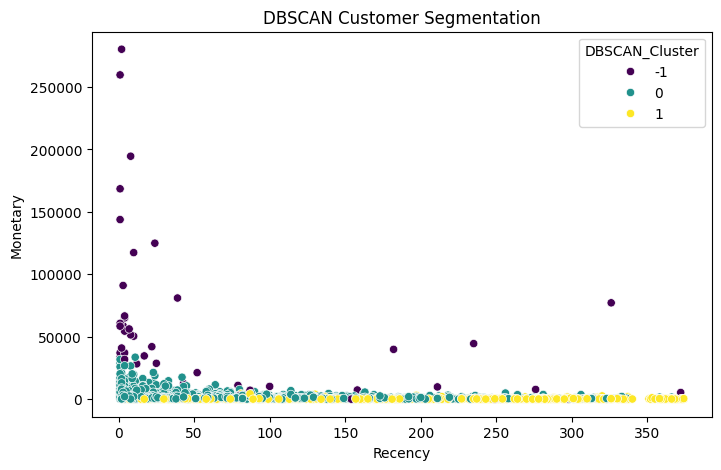

In [55]:

dbscan = DBSCAN(eps=0.5, min_samples=5)
rfm['DBSCAN_Cluster'] = dbscan.fit_predict(rfm_scaled)

plt.figure(figsize=(8, 5))

sns.scatterplot(
    x=rfm['Recency'],
    y=rfm['Monetary'],
    hue=rfm['DBSCAN_Cluster'],
    palette='viridis'
)

plt.title('DBSCAN Customer Segmentation')
plt.show()

In [56]:
pca = PCA(n_components=2)

pca_result = pca.fit_transform(rfm_scaled)

print(pca_result[:5])

print("Explained Variance:",
      pca.explained_variance_ratio_)

[[ 0.87265805  2.68675801]
 [ 2.5502599  -0.80442735]
 [ 0.47514179  0.74612088]
 [ 0.14583197 -0.46048047]
 [-1.68899049  0.67655549]]
Explained Variance: [0.75102042 0.18759201]


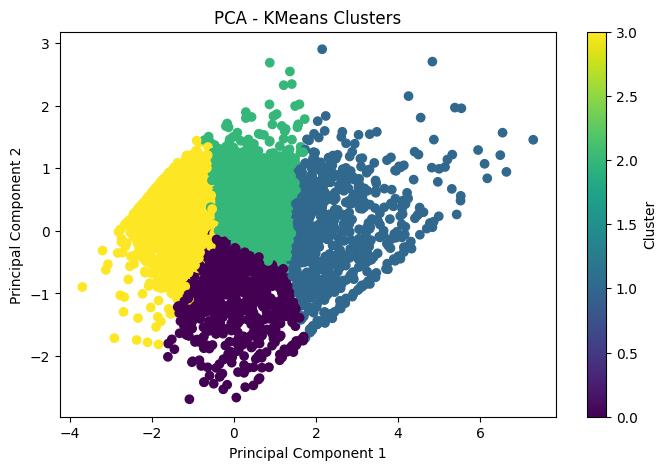

In [57]:
plt.figure(figsize=(8, 5))

plt.scatter(
    pca_result[:, 0],
    pca_result[:, 1],
    c=rfm['KMeans_Cluster'],
    cmap='viridis'
)

plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')
plt.title('PCA - KMeans Clusters')
plt.colorbar(label='Cluster')
plt.show()

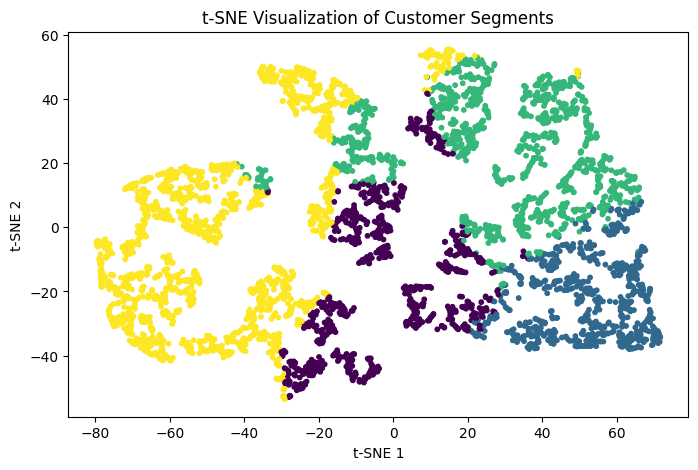

In [58]:
tsne = TSNE(
    n_components=2,
    random_state=42,
    perplexity=30,
    init='pca',
    learning_rate='auto'
)

tsne_result = tsne.fit_transform(rfm_scaled)

plt.figure(figsize=(8, 5))

plt.scatter(
    tsne_result[:, 0],
    tsne_result[:, 1],
    c=rfm['KMeans_Cluster'],
    cmap='viridis',
    s=10
)

plt.title('t-SNE Visualization of Customer Segments')
plt.xlabel('t-SNE 1')
plt.ylabel('t-SNE 2')
plt.show()

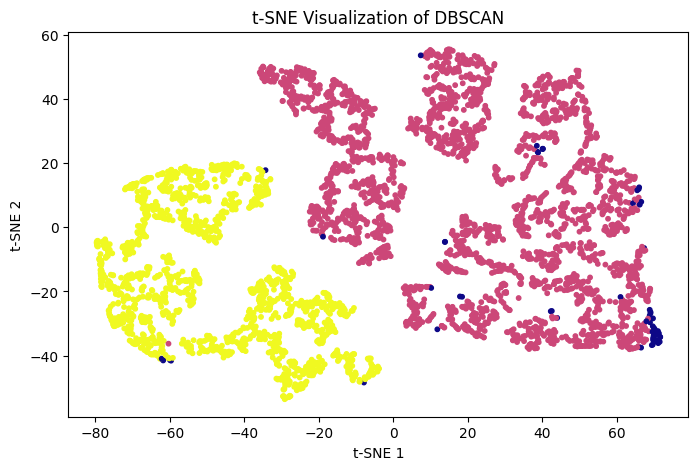

In [59]:
plt.figure(figsize=(8, 5))

plt.scatter(
    tsne_result[:, 0],
    tsne_result[:, 1],
    c=rfm['DBSCAN_Cluster'],
    cmap='plasma',
    s=10
)

plt.title('t-SNE Visualization of DBSCAN')
plt.xlabel('t-SNE 1')
plt.ylabel('t-SNE 2')
plt.show()

In [60]:
kmeans_score = silhouette_score(
    rfm_scaled,
    rfm['KMeans_Cluster']
)

print("KMeans Silhouette Score:", kmeans_score)

KMeans Silhouette Score: 0.3371343622222519


In [61]:
labels = rfm['DBSCAN_Cluster']

mask = labels != -1

if len(set(labels[mask])) >= 2:
    dbscan_score = silhouette_score(
        rfm_scaled[mask],
        labels[mask]
    )

    print("DBSCAN Silhouette Score:", dbscan_score)
else:
    print("DBSCAN did not produce enough clusters.")

DBSCAN Silhouette Score: 0.2930964433562129


In [62]:
persona = rfm.groupby('KMeans_Cluster').agg({
    'Recency': ['mean', 'count'],
    'Frequency': 'mean',
    'Monetary': 'mean'
})

# Flatten multi-index columns
persona.columns = ['Recency_Mean', 'Customer_Count', 'Frequency_Mean', 'Monetary_Mean']

print(persona)

                Recency_Mean  Customer_Count  Frequency_Mean  Monetary_Mean
KMeans_Cluster                                                             
0                  18.124253             837        2.148148     551.819534
1                  12.131285             716       13.713687    8074.266872
2                  71.084399            1173        4.083546    1802.829005
3                 182.496898            1612        1.318238     343.450032


In [63]:
dbscan_persona = rfm[rfm['DBSCAN_Cluster'] != -1].groupby(
    'DBSCAN_Cluster'
)[['Recency', 'Frequency', 'Monetary']].mean()

print(dbscan_persona)

                   Recency  Frequency     Monetary
DBSCAN_Cluster                                    
0                59.151200   5.370118  2029.042040
1               156.868013   1.000000   355.654021


In [64]:
rfm.to_csv(
    'Customer_Segmentation_Results.csv'
)

print("File saved successfully!")

File saved successfully!
